# Aula 11 – Métricas para classificação e análise em bases desbalanceadas

## Versão do aluno

### Objetivo da aula
Avaliar classificadores binários e interpretar corretamente as métricas, especialmente em uma base desbalanceada.

### Instruções
Complete as células indicadas ao longo da atividade e registre suas interpretações técnicas.  
Utilize também os gráficos para apoiar sua análise.


## 1. Importação das bibliotecas

Importe as bibliotecas necessárias para:
- leitura e manipulação da base;
- visualização;
- pré-processamento;
- treino de classificadores;
- cálculo das métricas de classificação.


In [ ]:
# Complete aqui
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, accuracy_score, precision_score, recall_score, f1_score, roc_curve, roc_auc_score)

pd.set_option('display.max_columns', None)

print("Bibliotecas importadas com sucesso!")

Bibliotecas importadas com sucesso!


## 2. Leitura da base

Leia o arquivo `dados_aula11_classificacao_desbalanceada.csv` e exiba as primeiras linhas.


In [ ]:
# Complete aqui
df = pd.read_csv('dados_aula11_classificacao_desbalanceada.csv')
df.head()

,id_registro,linha,turno,produto,temperatura_c,pressao_bar,vibracao_mm_s,abertura_valvula_pct,consumo_energia_kwh,tempo_resposta_s,erro_vazao_pct,leituras_invalidas,horas_operacao_bomba,falha_operacional
0,CLS_0001,Linha_C,Noite,Acido,32.33,4.54,2.40,72.08,20.05,1.41,4.32,3,572.9,0
1,CLS_0002,Linha_C,Manhã,Acido,47.27,4.51,2.56,48.98,18.24,NaN,4.74,4,402.0,1
2,CLS_0003,Linha_C,Manhã,Base,49.44,3.44,1.26,55.33,20.46,NaN,3.91,2,275.4,0
3,CLS_0004,Linha_C,Tarde,NaN,50.92,3.68,2.03,63.97,15.69,2.09,1.35,2,374.0,0
4,CLS_0005,Linha_B,Manhã,Base,60.52,3.68,2.61,64.77,18.79,1.04,2.45,1,477.5,0


## 3. Inspeção inicial da base

Verifique:
- dimensão da base;
- tipos de dados;
- valores faltantes;
- duplicatas;
- distribuição da variável-alvo.


In [ ]:
# Complete aqui
print('Dimensão da base:', df.shape)
print('\nTipos de dados:')
print(df.dtypes)
print('\nValores faltantes:')
print(df.isna().sum())
print('\nDuplicatas:', df.duplicated().sum())
print('\nDistribuição da variável-alvo:')
print(df['falha_operacional'].value_counts())

Dimensão da base: (430, 14)

Tipos de dados:
id_registro              object
linha                    object
turno                    object
produto                  object
temperatura_c           float64
pressao_bar             float64
vibracao_mm_s           float64
abertura_valvula_pct    float64
consumo_energia_kwh     float64
tempo_resposta_s        float64
erro_vazao_pct          float64
leituras_invalidas        int64
horas_operacao_bomba    float64
falha_operacional         int64
dtype: object

Valores faltantes:
id_registro             0
linha                   0
turno                   0
produto                 8
temperatura_c           8
pressao_bar             8
vibracao_mm_s           0
abertura_valvula_pct    0
consumo_energia_kwh     0
tempo_resposta_s        8
erro_vazao_pct          0
leituras_invalidas      0
horas_operacao_bomba    0
falha_operacional       0
dtype: int64

Duplicatas: 10

Distribuição da variável-alvo:
falha_operacional
0    371
1     59
Name: count,

**Registro do aluno:**  
- dimensão da base: 430 x 14
- tipos de dados: object, float64 e int64
- valores faltantes: 32
- duplicatas: 10
- distribuição da variável-alvo: 371 registros com 0 e 59 registros com 1.


## 4. Visualização do desbalanceamento

Calcule a distribuição da variável-alvo e crie um gráfico de barras.


In [ ]:
# Complete aqui
dist = df['falha_operacional'].value_counts().sort_index()
dist.index = ['Sem falha (0)', 'Falha (1)']
dist

,count
Sem falha (0),371
Falha (1),59


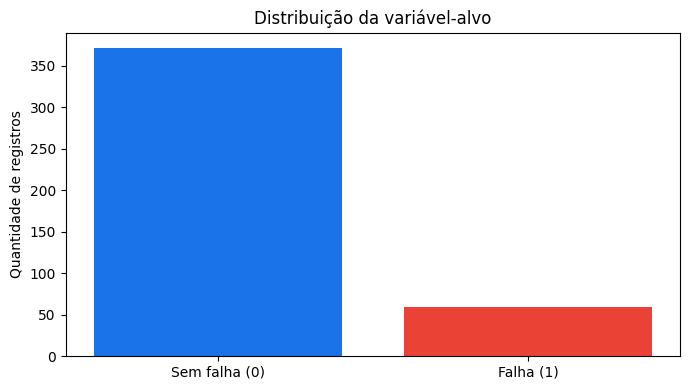

In [ ]:
# Gere o gráfico aqui
plt.figure(figsize=(7,4))
plt.bar(dist.index, dist.values, color=['#1A73E8', '#EA4335'])
plt.title('Distribuição da variável-alvo')
plt.ylabel('Quantidade de registros')
plt.tight_layout()
plt.show()

## 5. Limpeza básica

Remova as duplicatas da base.


In [ ]:
# Complete aqui
df = df.drop_duplicates().copy()
print(df.shape)

(420, 14)


## 6. Definição de X e y

Separe:
- `X`: variáveis de entrada;
- `y`: variável-alvo `falha_operacional`.

**Pergunta:**  
Por que `id_registro` não deve ser usado como variável preditora?


In [ ]:
# Complete aqui
X = df.drop(columns=['id_registro', 'falha_operacional'])
y = df['falha_operacional']

print(X.shape)
print(y.shape)

(420, 12)
(420,)


**Resposta do aluno:** Porque `id_registro` é uma variável que serve apenas para registrar a ordem dos registros, não tendo influência no funcionamento das máquinas.

## 7. Divisão em treino e teste

Faça a divisão com `stratify=y`.


In [ ]:
# Complete aqui
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size = 0.25, random_state = 42, stratify = y
)

print('Treino:', X_train.shape, y_train.shape)
print('Teste:', X_test.shape, y_test.shape)
print('\nDistribuição em y_train:')
print(y_train.value_counts())
print('\nDistribuição em y_test:')
print(y_test.value_counts())

Treino: (315, 12) (315,)
Teste: (105, 12) (105,)

Distribuição em y_train:
falha_operacional
0    271
1     44
Name: count, dtype: int64

Distribuição em y_test:
falha_operacional
0    90
1    15
Name: count, dtype: int64


**Pergunta:**  
Por que o uso de `stratify=y` é importante nesta aula?


**Resposta do aluno:**  
Para manter a mesma proporção nos conjutos de treino e teste, visto que a grande maioria dos dados de `falha_operacional` estão como `0`, sem esse parâmetro, correria o risco de não ter dados suficientes para entender as causas do `1`.

## 8. Pré-processamento com pipeline

Monte um pipeline com:
- imputação da mediana + padronização para numéricas;
- imputação da moda + one-hot encoding para categóricas.


In [ ]:
# Complete aqui
colunas_numericas = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
colunas_categoricas = X.select_dtypes(include=['object']).columns.tolist()

transformador_numerico = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

transformador_categorico = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessador = ColumnTransformer(transformers=[
    ('num', transformador_numerico, colunas_numericas),
    ('cat', transformador_categorico, colunas_categoricas)
])

## 9. Criação de dois classificadores

Crie:
- um modelo de Regressão Logística;
- um modelo de Árvore de Decisão Classificadora.

### Observação
Como o problema é de **classificação binária**, as métricas mais adequadas são métricas de classificação, como acurácia, precisão, recall, F1-score, especificidade e AUC.


In [ ]:
# Complete aqui
modelo_logistico = Pipeline(steps=[
    ('preprocessador', preprocessador),
    ('modelo', LogisticRegression(max_iter=1000))
])

modelo_arvore = Pipeline(steps=[
    ('preprocessador', preprocessador),
    ('modelo', DecisionTreeClassifier(max_depth=5, random_state=42))
])

## 10. Treino dos modelos

Treine os dois classificadores.


In [ ]:
# Complete aqui
modelo_logistico.fit(X_train, y_train)
modelo_arvore.fit(X_train, y_train)

print('Modelos treinados com sucesso.')

Modelos treinados com sucesso.


## 11. Predições e probabilidades

Gere:
- as classes previstas;
- as probabilidades da classe positiva.


In [ ]:
# Complete aqui
pred_log = modelo_logistico.predict(X_test)
pred_tree = modelo_arvore.predict(X_test)

proba_log = modelo_logistico.predict_proba(X_test)[:, 1]
proba_tree = modelo_arvore.predict_proba(X_test)[:, 1]

## 12. Matriz de confusão

Calcule a matriz de confusão dos dois modelos e gere a visualização.


In [ ]:
# Complete aqui
cm_log = confusion_matrix(y_test, pred_log)
cm_tree = confusion_matrix(y_test, pred_tree)

print(cm_log)
print(cm_tree)

[[85  5]
 [ 7  8]]
[[83  7]
 [ 8  7]]


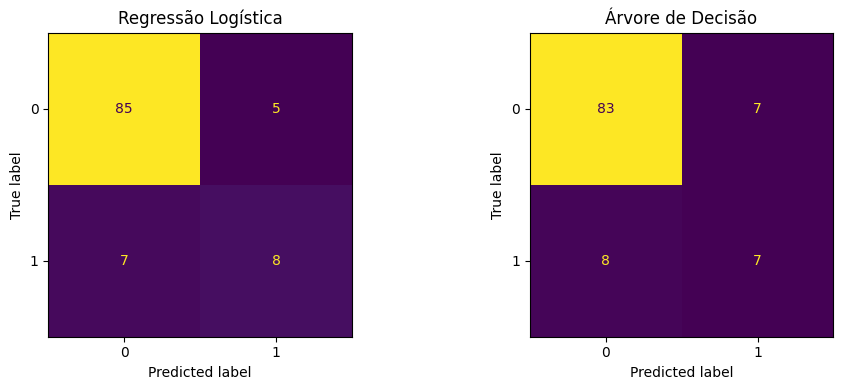

In [ ]:
# Gere a visualização aqui
fig, axes = plt.subplots(1, 2, figsize=(10,4))

ConfusionMatrixDisplay(cm_log).plot(ax=axes[0], colorbar=False)
axes[0].set_title('Regressão Logística')

ConfusionMatrixDisplay(cm_tree).plot(ax=axes[1], colorbar=False)
axes[1].set_title('Árvore de Decisão')

plt.tight_layout()
plt.show()

## 13. Cálculo das métricas

Calcule:
- Acurácia
- Precisão
- Recall
- F1-score
- Especificidade
- AUC


In [ ]:
# Complete aqui
def especificidade(y_real, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_real, y_pred).ravel()
    return tn / (tn + fp)

metricas = pd.DataFrame({
    'Modelo': ['Regressão Logística', 'Árvore de Decisão'],
    'Acurácia': [
        accuracy_score(y_test, pred_log),
        accuracy_score(y_test, pred_tree)
    ],
    'Precisão': [
        precision_score(y_test, pred_log, zero_division=0),
        precision_score(y_test, pred_tree, zero_division=0)
    ],
    'Recall': [
        recall_score(y_test, pred_log, zero_division=0),
        recall_score(y_test, pred_tree, zero_division=0)
    ],
    'F1-score': [
        f1_score(y_test, pred_log, zero_division=0),
        f1_score(y_test, pred_tree, zero_division=0)
    ],
    'Especificidade': [
        especificidade(y_test, pred_log),
        especificidade(y_test, pred_tree)
    ],
    'AUC': [
        roc_auc_score(y_test, proba_log),
        roc_auc_score(y_test, proba_tree)
    ]
}).round(4)

metricas

,Modelo,Acurácia,Precisão,Recall,F1-score,Especificidade,AUC
0,Regressão Logística,0.8857,0.6154,0.5333,0.5714,0.9444,0.9170
1,Árvore de Decisão,0.8571,0.5000,0.4667,0.4828,0.9222,0.7874


## 14. Visualização comparativa das métricas

Crie gráficos comparando os dois classificadores.


In [ ]:
# Complete aqui
metricas_plot = metricas.set_index('Modelo')

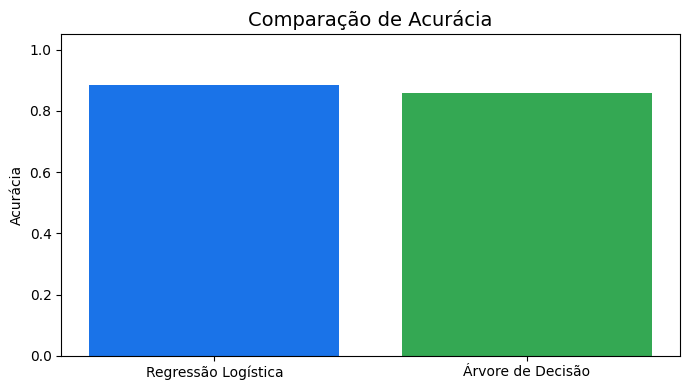

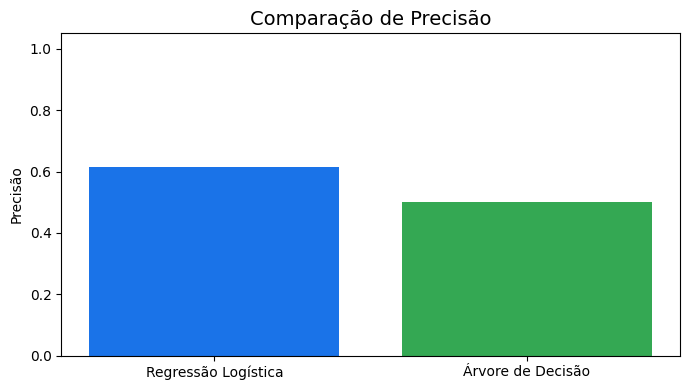

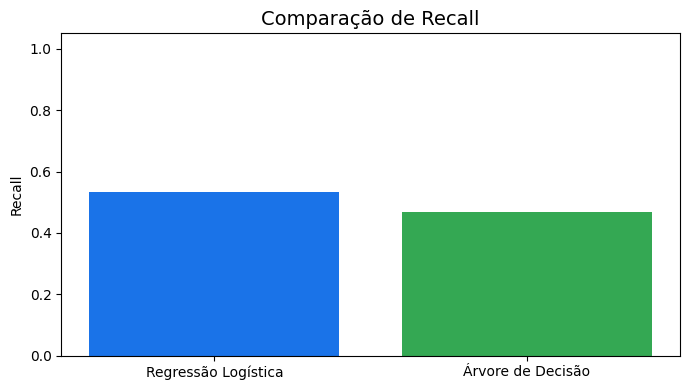

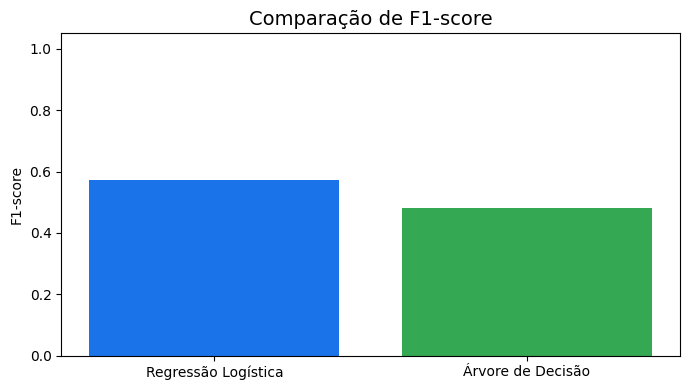

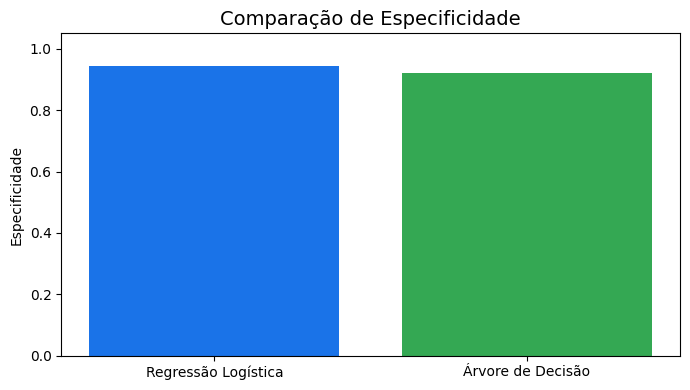

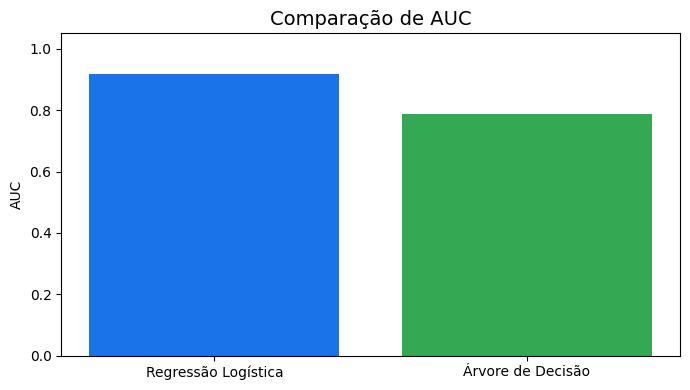

In [ ]:
# Gere os gráficos aqui para Acurácia, Precisão, Recall, F1-score, Especificidade e AUC
for coluna in ['Acurácia', 'Precisão', 'Recall', 'F1-score', 'Especificidade', 'AUC']:
  plt.figure(figsize=(7, 4))
  plt.bar(metricas_plot.index, metricas_plot[coluna], color=['#1A73E8', '#34A853'])
  plt.title(f'Comparação de {coluna}', fontsize=14)
  plt.ylim(0, 1.05)
  plt.ylabel(coluna)
  plt.tight_layout()
  plt.show()

## 15. Curva ROC

Calcule a curva ROC e faça o gráfico comparativo dos dois modelos.


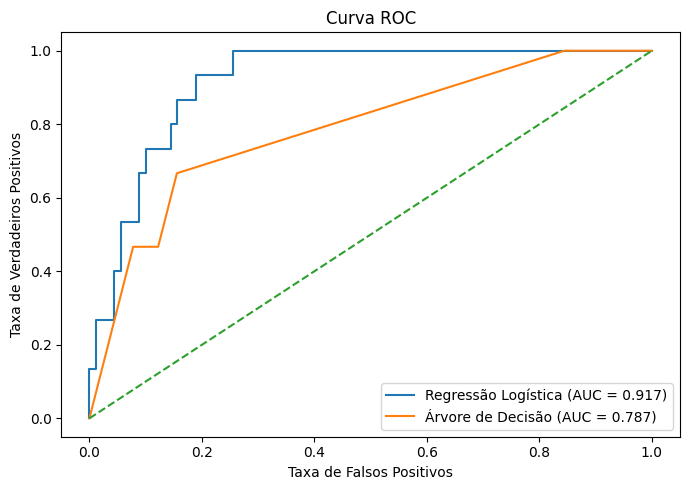

In [ ]:
# Complete aqui
fpr_log, tpr_log, _ = roc_curve(y_test, proba_log)
fpr_tree, tpr_tree, _ = roc_curve(y_test, proba_tree)

plt.figure(figsize=(7,5))
plt.plot(fpr_log, tpr_log, label=f'Regressão Logística (AUC = {roc_auc_score(y_test, proba_log):.3f})')
plt.plot(fpr_tree, tpr_tree, label=f'Árvore de Decisão (AUC = {roc_auc_score(y_test, proba_tree):.3f})')
plt.plot([0, 1], [0, 1], linestyle='--')
plt.xlabel('Taxa de Falsos Positivos')
plt.ylabel('Taxa de Verdadeiros Positivos')
plt.title('Curva ROC')
plt.legend()
plt.tight_layout()
plt.show()

## 16. Acurácia em bases desbalanceadas

Monte um baseline que prevê sempre a classe majoritária e compare suas métricas com as dos modelos treinados.


In [ ]:
# Complete aqui
classe_majoritaria = y_test.mode()[0]
baseline_pred = np.full_like(y_test, fill_value=classe_majoritaria)

baseline_acc = accuracy_score(y_test, baseline_pred)
baseline_rec = recall_score(y_test, baseline_pred, zero_division=0)
baseline_pre = precision_score(y_test, baseline_pred, zero_division=0)
baseline_f1 = f1_score(y_test, baseline_pred, zero_division=0)

pd.DataFrame({
    'Modelo': ['Baseline classe majoritária'],
    'Acurácia': [baseline_acc],
    'Precisão': [baseline_pre],
    'Recall': [baseline_rec],
    'F1-score': [baseline_f1]
}).round(4)

,Modelo,Acurácia,Precisão,Recall,F1-score
0,Baseline classe majoritária,0.8571,0.0,0.0,0.0


## 17. Interpretação orientada

Escreva:
- qual modelo detecta melhor as falhas;
- qual modelo parece mais equilibrado;
- qual métrica parece mais importante para este problema industrial.


**Resposta do aluno:**  
- Melhor para detectar falhas: Regressão Lógica
- Modelo mais equilibrado: Árvore de Decisão
- Métrica mais importante: O AUC, quanto maior, maior a capacidade discriminatória.


## 18. Síntese sobre bases desbalanceadas

Explique, com suas palavras, por que a acurácia isolada pode ser insuficiente em bases desbalanceadas.


**Resposta do aluno:**  


## 19. Exportação dos resultados

Salve:
- a tabela de métricas;
- a matriz de confusão da regressão logística;
- a matriz de confusão da árvore.


In [ ]:
# Complete aqui
metricas.to_csv('metricas_classificacao_aula11', index=False)

pd.DataFrame(cm_log, columns=['Pred_0', 'Pred_1'], index=['Real_0', 'Real_1']).to_csv(
    'matriz_confusao_logistica_aula11'
)
pd.DataFrame(cm_tree, columns=['Pred_0', 'Pred_1'], index=['Real_0', 'Real_1']).to_csv(
    'matriz_confusao_arvore_aula11'
)

print('Arquivos exportados com sucesso.')

Arquivos exportados com sucesso.


## 20. Fechamento

Verifique se você:
- calculou corretamente as métricas de classificação;
- interpretou a matriz de confusão com coerência;
- justificou a métrica mais adequada ao problema;
- analisou criticamente o desbalanceamento da base.
